In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Salary_Data.csv")

print("Shape:")
print(df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nDescription:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Saving Salary_Data.csv to Salary_Data.csv
Shape:
(30, 2)

First five rows:
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0

Description:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000

Missing values:
YearsExperience    0
Salary             0
dtype: int64


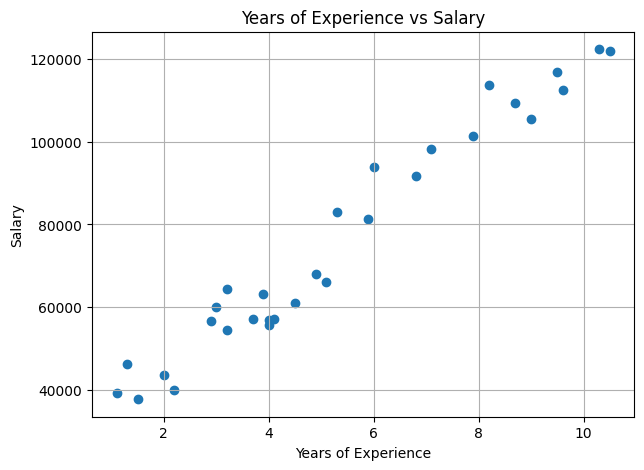

Pearson Correlation Coefficient: 0.9782416184887599


In [2]:
plt.figure(figsize=(7, 5))

plt.scatter(df["YearsExperience"], df["Salary"])

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")
plt.grid(True)
plt.show()

correlation = df["YearsExperience"].corr(df["Salary"])

print("Pearson Correlation Coefficient:", correlation)

In [3]:
X = df[["YearsExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (20, 1)
Testing data shape: (10, 1)


In [4]:
model = LinearRegression()

model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

print("Slope:", slope)
print("Intercept:", intercept)

print("Regression Equation:")
print("Salary =", slope, "* YearsExperience +", intercept)

Slope: 9345.942443122372
Intercept: 26816.192244031183
Regression Equation:
Salary = 9345.942443122372 * YearsExperience + 26816.192244031183


In [5]:
y_pred = model.predict(X_test)

print("Predicted salaries for test data:")
print(y_pred)

experience = pd.DataFrame({
    "YearsExperience": [5, 12]
})

predicted_salary = model.predict(experience)

print("\nSalary prediction for 5 years:", predicted_salary[0])
print("Salary prediction for 12 years:", predicted_salary[1])

Predicted salaries for test data:
[ 40835.10590871 123079.39940819  65134.55626083  63265.36777221
 115602.64545369 108125.8914992  116537.23969801  64199.96201652
  76349.68719258 100649.1375447 ]

Salary prediction for 5 years: 73545.90445964305
Salary prediction for 12 years: 138967.50156149964


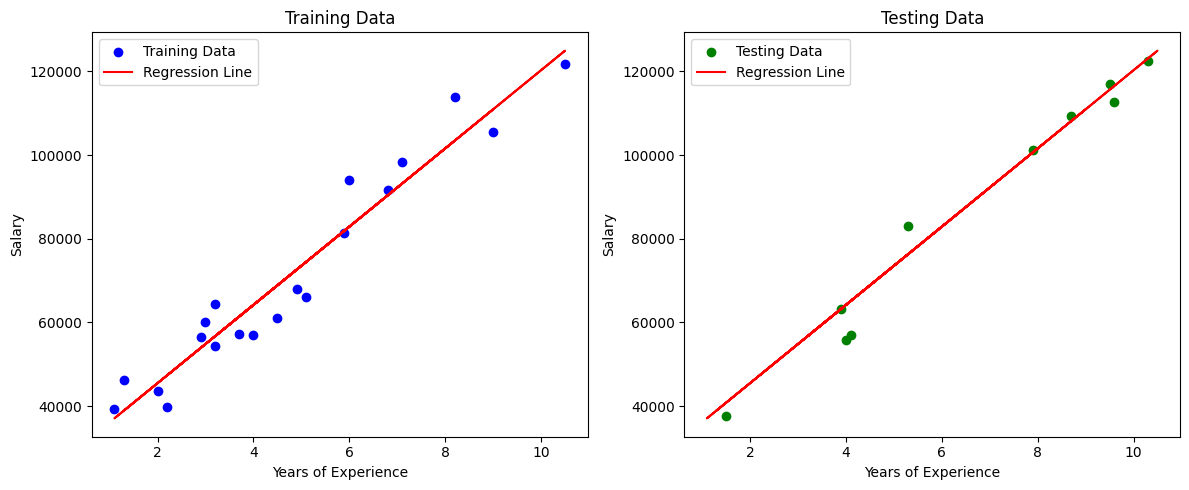

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train, y_train, color="blue", label="Training Data")
plt.plot(X_train, model.predict(X_train), color="red", label="Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Training Data")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(X_test, y_test, color="green", label="Testing Data")
plt.plot(X_train, model.predict(X_train), color="red", label="Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Testing Data")
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
def calculate_mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)


def calculate_mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))


mse = calculate_mse(y_test, y_pred)
mae = calculate_mae(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

print("\nVerification using sklearn:")
print("Sklearn MSE:", mean_squared_error(y_test, y_pred))
print("Sklearn MAE:", mean_absolute_error(y_test, y_pred))

MSE: 21026037.329511296
MAE: 3426.4269374307078
RMSE: 4585.4157204675885
R2 Score: 0.9749154407708353

Verification using sklearn:
Sklearn MSE: 21026037.329511296
Sklearn MAE: 3426.4269374307078


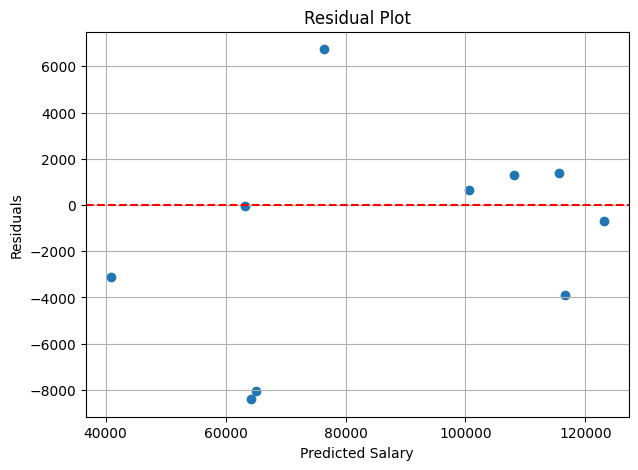

In [8]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

In [9]:
X_array = X_train.values.flatten()
y_array = y_train.values

X_matrix = np.column_stack((np.ones(len(X_array)), X_array))

coefficients = np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T @ y_array

ols_intercept = coefficients[0]
ols_slope = coefficients[1]

print("OLS from Scratch:")
print("Slope:", ols_slope)
print("Intercept:", ols_intercept)

print("\nScikit-learn:")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

OLS from Scratch:
Slope: 9345.942443122372
Intercept: 26816.19224403121

Scikit-learn:
Slope: 9345.942443122372
Intercept: 26816.192244031183


In [10]:
random_states = [0, 1, 2, 3, 4]

results = []

for state in random_states:
    X_train_rs, X_test_rs, y_train_rs, y_test_rs = train_test_split(
        X, y, train_size=2/3, random_state=state
    )

    temp_model = LinearRegression()
    temp_model.fit(X_train_rs, y_train_rs)

    predictions = temp_model.predict(X_test_rs)

    score = r2_score(y_test_rs, predictions)

    results.append({
        "Random State": state,
        "R2 Score": score
    })

results_df = pd.DataFrame(results)

print(results_df)

   Random State  R2 Score
0             0  0.974915
1             1  0.924085
2             2  0.904180
3             3  0.943436
4             4  0.946808


In [12]:
uploaded = files.upload()

penguins = pd.read_csv("penguins_size.csv")

print("First five rows:")
print(penguins.head())

print("\nShape:")
print(penguins.shape)

print("\nMissing values in each column:")
print(penguins.isnull().sum())

Saving penguins_size.csv to penguins_size.csv
First five rows:
  species     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen              39.1             18.7              181.0   
1  Adelie  Torgersen              39.5             17.4              186.0   
2  Adelie  Torgersen              40.3             18.0              195.0   
3  Adelie  Torgersen               NaN              NaN                NaN   
4  Adelie  Torgersen              36.7             19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  

Shape:
(344, 7)

Missing values in each column:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


In [13]:
print("Unique values in sex column:")
print(penguins["sex"].unique())

penguins = penguins[
    penguins["sex"].isin(["MALE", "FEMALE"]) |
    penguins["sex"].isnull()
].copy()

print("\nDataset after removing invalid entries:")
print(penguins.shape)

print("\nRemaining sex values:")
print(penguins["sex"].unique())

Unique values in sex column:
['MALE' 'FEMALE' nan '.']

Dataset after removing invalid entries:
(343, 7)

Remaining sex values:
['MALE' 'FEMALE' nan]


In [14]:
# (a) Remove rows with missing values
penguins_drop = penguins.dropna()

# (b) Mean imputation for numeric columns and mode imputation for sex
penguins_mean = penguins.copy()

numeric_columns = penguins_mean.select_dtypes(include=np.number).columns

for column in numeric_columns:
    penguins_mean[column] = penguins_mean[column].fillna(
        penguins_mean[column].mean()
    )

penguins_mean["sex"] = penguins_mean["sex"].fillna(
    penguins_mean["sex"].mode()[0]
)

# (c) Median imputation within each species
penguins_median = penguins.copy()

for column in numeric_columns:
    penguins_median[column] = penguins_median.groupby("species")[column].transform(
        lambda x: x.fillna(x.median())
    )

print("Original Dataset Shape:", penguins.shape)
print("After Dropping Missing Values:", penguins_drop.shape)
print("After Mean Imputation:", penguins_mean.shape)
print("After Median Imputation:", penguins_median.shape)

Original Dataset Shape: (343, 7)
After Dropping Missing Values: (333, 7)
After Mean Imputation: (343, 7)
After Median Imputation: (343, 7)


           body_mass_g  flipper_length_mm
species                                  
Adelie     3700.662252         189.953642
Chinstrap  3733.088235         195.823529
Gentoo     5077.663934         217.188525


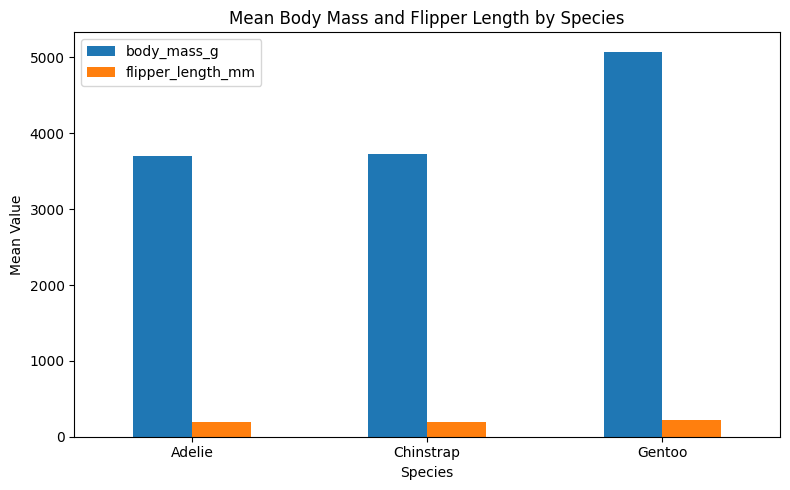

In [15]:
species_mean = penguins.groupby("species")[
    ["body_mass_g", "flipper_length_mm"]
].mean()

print(species_mean)

species_mean.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Species")
plt.ylabel("Mean Value")
plt.title("Mean Body Mass and Flipper Length by Species")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
from sklearn.preprocessing import LabelEncoder

categorical_columns = ["species", "island", "sex"]

encoded_cat = penguins[categorical_columns].copy()

for column in categorical_columns:
    encoded_cat[column] = encoded_cat[column].astype("category")
    encoded_cat[column + "_cat_codes"] = encoded_cat[column].cat.codes

print("Category Codes:")
print(encoded_cat)

print("\nUsing LabelEncoder:")

for column in categorical_columns:
    le = LabelEncoder()
    valid_values = penguins[column].dropna()
    le.fit(valid_values)

    encoded_values = penguins[column].map(
        lambda value: le.transform([value])[0] if pd.notna(value) else -1
    )

    print(column, ":", encoded_values.tolist())

Category Codes:
    species     island     sex  species_cat_codes  island_cat_codes  \
0    Adelie  Torgersen    MALE                  0                 2   
1    Adelie  Torgersen  FEMALE                  0                 2   
2    Adelie  Torgersen  FEMALE                  0                 2   
3    Adelie  Torgersen     NaN                  0                 2   
4    Adelie  Torgersen  FEMALE                  0                 2   
..      ...        ...     ...                ...               ...   
339  Gentoo     Biscoe     NaN                  2                 0   
340  Gentoo     Biscoe  FEMALE                  2                 0   
341  Gentoo     Biscoe    MALE                  2                 0   
342  Gentoo     Biscoe  FEMALE                  2                 0   
343  Gentoo     Biscoe    MALE                  2                 0   

     sex_cat_codes  
0                1  
1                0  
2                0  
3               -1  
4                0  
..   

In [17]:
penguins_encoded = penguins_median.copy()

encoded_columns = pd.get_dummies(
    penguins_encoded[["island", "sex"]],
    drop_first=True,
    dtype=int
)

numeric_features = penguins_encoded[
    ["culmen_length_mm", "culmen_depth_mm",
     "flipper_length_mm", "body_mass_g"]
]

final_features = pd.concat(
    [numeric_features, encoded_columns],
    axis=1
)

print("Final Feature Matrix:")
print(final_features.head())

print("\nFeature Matrix Shape:")
print(final_features.shape)

Final Feature Matrix:
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  \
0              39.1             18.7              181.0       3750.0   
1              39.5             17.4              186.0       3800.0   
2              40.3             18.0              195.0       3250.0   
3              38.8             18.4              190.0       3700.0   
4              36.7             19.3              193.0       3450.0   

   island_Dream  island_Torgersen  sex_MALE  
0             0                 1         1  
1             0                 1         0  
2             0                 1         0  
3             0                 1         0  
4             0                 1         0  

Feature Matrix Shape:
(343, 7)


In [18]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

numeric_columns = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

numeric_data = penguins_median[numeric_columns]

print("Before Scaling:")
print(numeric_data.describe())

standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(numeric_data)

standard_df = pd.DataFrame(
    standard_scaled,
    columns=numeric_columns
)

print("\nAfter Standard Scaling:")
print(standard_df.describe())

minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(numeric_data)

minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=numeric_columns
)

print("\nAfter MinMax Scaling:")
print(minmax_df.describe())

Before Scaling:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
count        343.000000       343.000000         343.000000   343.000000
mean          43.915160        17.152770         200.880466  4200.728863
std            5.461589         1.974927          14.050254   801.649556
min           32.100000        13.100000         172.000000  2700.000000
25%           39.200000        15.550000         190.000000  3550.000000
50%           44.400000        17.300000         197.000000  4050.000000
75%           48.500000        18.700000         213.000000  4750.000000
max           59.600000        21.500000         231.000000  6300.000000

After Standard Scaling:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm   body_mass_g
count      3.430000e+02     3.430000e+02       3.430000e+02  3.430000e+02
mean       1.657243e-15    -4.143106e-17       6.628970e-16 -5.386038e-16
std        1.001461e+00     1.001461e+00       1.001461e+00  1.001461e+00
min   

In [19]:
penguins_q18 = penguins_median.dropna(
    subset=["flipper_length_mm", "body_mass_g"]
)

X_penguin = penguins_q18[["flipper_length_mm"]]
y_penguin = penguins_q18["body_mass_g"]

penguin_model = LinearRegression()
penguin_model.fit(X_penguin, y_penguin)

predictions = penguin_model.predict(X_penguin)

print("Slope:", penguin_model.coef_[0])
print("Intercept:", penguin_model.intercept_)

print("\nRegression Equation:")
print("Body Mass =", penguin_model.coef_[0],
      "* Flipper Length +", penguin_model.intercept_)

print("\nR2 Score:", r2_score(y_penguin, predictions))

Slope: 49.725611788851715
Intercept: -5788.17522879143

Regression Equation:
Body Mass = 49.725611788851715 * Flipper Length + -5788.17522879143

R2 Score: 0.7595555266909723


In [20]:
model_data = final_features.dropna()

X_multiple = model_data.drop(columns=["body_mass_g"])
y_multiple = model_data["body_mass_g"]

multiple_model = LinearRegression()
multiple_model.fit(X_multiple, y_multiple)

multiple_predictions = multiple_model.predict(X_multiple)

print("Multiple Linear Regression")
print("Coefficients:", multiple_model.coef_)
print("Intercept:", multiple_model.intercept_)

print("\nR2 Score:", r2_score(y_multiple, multiple_predictions))

print("\nSingle Feature Model R2:")
print(r2_score(y_penguin, penguin_model.predict(X_penguin)))

Multiple Linear Regression
Coefficients: [   7.61335929  -44.92692385   33.67008589 -325.9996059  -197.92849323
  472.03459395]
Intercept: -2209.9942935255394

R2 Score: 0.8349902891573603

Single Feature Model R2:
0.7595555266909723


In [21]:
arr = np.arange(1, 11)

print("Original 1D Array:")
print(arr)

print("\nReshape:")
print(arr.reshape(2, 5))

print("\nFlatten:")
matrix = arr.reshape(2, 5)
print(matrix.flatten())

print("\nTranspose:")
print(matrix.T)

print("\nResize to (3, 4):")
print(np.resize(arr, (3, 4)))

Original 1D Array:
[ 1  2  3  4  5  6  7  8  9 10]

Reshape:
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]]

Flatten:
[ 1  2  3  4  5  6  7  8  9 10]

Transpose:
[[ 1  6]
 [ 2  7]
 [ 3  8]
 [ 4  9]
 [ 5 10]]

Resize to (3, 4):
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10  1  2]]


In [22]:
A = np.array([
    [1, 2, 3],
    [2, 4, 6],
    [3, 8, 9]
])

B = np.array([
    [1, 1, 3],
    [1, 2, 4],
    [1, 3, 0]
])

matrices = {"Matrix A": A, "Matrix B": B}

for name, matrix in matrices.items():
    print("\n", name)
    print(matrix)

    print("Determinant:", np.linalg.det(matrix))
    print("Rank:", np.linalg.matrix_rank(matrix))
    print("Trace:", np.trace(matrix))

    if np.linalg.det(matrix) != 0:
        print("Inverse:")
        print(np.linalg.inv(matrix))
    else:
        print("Inverse does not exist because the matrix is singular.")


 Matrix A
[[1 2 3]
 [2 4 6]
 [3 8 9]]
Determinant: 0.0
Rank: 2
Trace: 14
Inverse does not exist because the matrix is singular.

 Matrix B
[[1 1 3]
 [1 2 4]
 [1 3 0]]
Determinant: -5.000000000000001
Rank: 3
Trace: 3
Inverse:
[[ 2.4 -1.8  0.4]
 [-0.8  0.6  0.2]
 [-0.2  0.4 -0.2]]


In [23]:
df1 = pd.DataFrame({
    "Name": ["Amit", "Priya", "Rahul"],
    "Age": [21, 22, 20]
})

df2 = pd.DataFrame({
    "Name": ["Sneha", "Rohan", "Neha"],
    "Age": [23, 21, 22]
})

print("First DataFrame:")
print(df1)

print("\nSecond DataFrame:")
print(df2)

print("\nRow-wise Concatenation:")
row_concat = pd.concat([df1, df2], axis=0, ignore_index=True)
print(row_concat)

print("\nColumn-wise Concatenation:")
column_concat = pd.concat([df1, df2], axis=1)
print(column_concat)

print("\nSorted by Name:")
sorted_df = row_concat.sort_values(by="Name")
print(sorted_df)

print("\nRenaming Age Column:")
renamed_df = row_concat.rename(columns={"Age": "Employee_Age"})
print(renamed_df)

print("\nSummary Statistics:")
print(row_concat.describe())

First DataFrame:
    Name  Age
0   Amit   21
1  Priya   22
2  Rahul   20

Second DataFrame:
    Name  Age
0  Sneha   23
1  Rohan   21
2   Neha   22

Row-wise Concatenation:
    Name  Age
0   Amit   21
1  Priya   22
2  Rahul   20
3  Sneha   23
4  Rohan   21
5   Neha   22

Column-wise Concatenation:
    Name  Age   Name  Age
0   Amit   21  Sneha   23
1  Priya   22  Rohan   21
2  Rahul   20   Neha   22

Sorted by Name:
    Name  Age
0   Amit   21
5   Neha   22
1  Priya   22
2  Rahul   20
4  Rohan   21
3  Sneha   23

Renaming Age Column:
    Name  Employee_Age
0   Amit            21
1  Priya            22
2  Rahul            20
3  Sneha            23
4  Rohan            21
5   Neha            22

Summary Statistics:
             Age
count   6.000000
mean   21.500000
std     1.048809
min    20.000000
25%    21.000000
50%    21.500000
75%    22.000000
max    23.000000
